To find formal academic lectures, tutorials, and materials covering the concepts in your text—specifically Color Quantization, Image Compression, and Octrees—you can access the following resources:

1. **MIT OpenCourseWare (OCW)**

MIT covers these topics across Computer Science (Data Structures/Algorithms) and Electrical Engineering (Signal/Image Processing) courses:
- 6.006 / 6.046J (Introduction to Algorithms / Design and Analysis of Algorithms): These courses formally cover hierarchical data structures, spatial trees, and multi-way trees (like Quadtrees and Octrees) used for partitioning multi-dimensional spaces.
- 6.02 (Introduction to EECS II: Digital Communication Systems): This course has dedicated modules and notes on Source Coding and Compression, which walk through the mathematical foundations of reducing image memory size (like the bits/bytes conversions mentioned in your text) and Huffman coding.
- 6.341 (Discrete-Time Signal Processing) & 6.815 (Digital and Computational Photography): These advanced courses discuss how the human eye perceives color, how the continuous physical world is discretized (sampling and quantization), and specific color space reductions.

2. **Khan Academy**

While Khan Academy does not have a specific data structures course covering Octrees, they have excellent introductory material on the underlying foundational concepts:
- Computer Science / Pixels and Color: Under their "Digital Information" and Pixars in a Box paths, they offer highly visual, interactive lessons explaining how images are represented by pixels, how the RGB color space creates 16.7 million combinations, and how quantization works geometrically.
- Information Theory: Their cryptography and information theory sections explain data density, bit-reduction, and the math behind why smaller file sizes save internet bandwidth.

3. **Other Formal Academic Alternatives**

If you want to see the exact implementation of an Octree for Color Quantization explained step-by-step in a lecture format:
- Coursera / Princeton University (Algorithms, Part I & II by Robert Sedgewick): This is one of the gold standards for tree-based spatial partitioning. They focus heavily on geometric applications of trees (like Kd-Trees and Quadtrees), which share the exact same logic as the Octree splitting your 3D color cube.
- Open Data Structures (opendatastructures.org): A completely free, highly formal academic textbook and resource that provides theoretical proofs and multi-language code for specialized tree geometries.
Would you like help translating the bit-shifting logic (compute_index) from your text into a simpler explanation, or would you prefer a link to a specific syllabus/lecture note from the courses mentioned?


others:
- Deterministic Finite State Machines - Theory of Computation
TrevTutor: https://youtu.be/zF3RjLpYMUE?si=E4DfmONMY6ByIx0k

In [7]:
import sys
from random import randrange
from PIL import Image

class Octree:
    """
    Implements the Octree data structure for adaptive color quantization.
    
    Why use an Octree for images?
    Instead of uniformly dividing the 256x256x256 color cube (which wastes memory on 
    unused colors), an octree dynamically adapts to the actual colors present in the image.
    Popular colors get smaller sub-cubes, while unused color spaces are merged away.
    """
    def __init__(self):
        self.root = None
        # Limits depth to 5 (ignores 2 least significant bits). 
        # Optimization: Keeps tree size manageable without impacting visual quality.
        self.max_level = 5  
        self.num_leaves = 0
        self.all_leaves = []  # Direct reference list to leaves for fast access during reduction

    def insert(self, r, g, b):
        """Inserts a pixel's RGB color into the octree structure."""
        if not self.root:
            self.root = self.OTNode(outer=self)
        self.root.insert(r, g, b, 0, self)

    def find(self, r, g, b):
        """Searches for an exact or quantized color approximation in the octree."""
        if self.root:
            return self.root.find(r, g, b, 0)
        return (0, 0, 0)

    def reduce(self, max_cubes):
        """
        Reduces the octree until the number of leaf nodes is <= max_cubes (e.g., 256).
        
        Revision Note (The Reduction Loop):
        1. Finds the leaf with the smallest reference count (fewest pixels using it) at the deepest level.
        2. Merges that leaf and its siblings back into their parent node.
        3. Repeats until we hit our target color palette size.
        """
        while len(self.all_leaves) > max_cubes:
            smallest = self.find_min_cube()
            if smallest and smallest.parent:
                smallest.parent.merge()
                # The parent node becomes the new leaf node after merging its children
                self.all_leaves.append(smallest.parent)
                self.num_leaves = self.num_leaves + 1

    def find_min_cube(self):
        """Helper to find the deepest leaf node with the smallest reference count."""
        min_count = sys.maxsize
        max_level = 0
        min_cube = None
        for i in self.all_leaves:
            if i.count <= min_count and i.level >= max_level:
                min_cube = i
                min_count = i.count
                max_level = i.level
        return min_cube

    class OTNode:
        """
        Inner class representing a node in the octree.
        
        Why an inner class?
        `OTNode` needs access to Octree's attributes (`max_level`, `all_leaves`), 
        and nodes are an implementation detail hidden from outside code (information hiding).
        Each node can have up to 8 children (0-7), representing 3D sub-cubes.
        """
        def __init__(self, parent=None, level=0, outer=None):
            self.red = 0
            self.green = 0
            self.blue = 0
            self.count = 0           # Reference count: how many pixels map to this node
            self.parent = parent
            self.level = level
            self.o_tree = outer      # Reference back to the parent Octree instance
            self.children = [None] * 8  # 8 children for the 8 octants of the color cube

        def insert(self, r, g, b, level, outer):
            """Recursively traverses or builds the tree branch for a given RGB color."""
            if level < outer.max_level:
                # 1. Compute which child branch (0-7) this color belongs to
                idx = self.compute_index(r, g, b, level)
                
                # 2. Create child node if it doesn't exist yet
                if self.children[idx] is None:
                    self.children[idx] = outer.OTNode(
                        parent=self,
                        level=level + 1,
                        outer=outer
                    )
                # 3. Recurse down into the child
                self.children[idx].insert(r, g, b, level + 1, outer)
            else:
                # Reached leaf level: store/accumulate color values
                if self.count == 0:
                    outer.num_leaves += 1
                    outer.all_leaves.append(self)
                self.red += r
                self.green += g
                self.blue += b
                self.count += 1

        def compute_index(self, r, g, b, l):
            """
            Computes the 3-bit child index (0 to 7) using bitwise shifts and masks.
            
            How it works:
            It extracts 1 bit from Red, Green, and Blue at the current tree depth (`l`)
            and combines them using bitwise OR (|) to form an index between 0 and 7.
            """
            shift = 8 - l
            rc = (r >> (shift - 2)) & 0x4
            gc = (g >> (shift - 1)) & 0x2
            bc = (b >> shift) & 0x1
            return rc | gc | bc

        def find(self, r, g, b, level):
            """Traverses the tree to find the matching leaf node and return its average color."""
            if level < self.o_tree.max_level:
                idx = self.compute_index(r, g, b, level)
                if self.children[idx]:
                    return self.children[idx].find(r, g, b, level + 1)
                elif self.count > 0:
                    # Fallback if node was reduced/merged early
                    return (
                        self.red // self.count,
                        self.green // self.count,
                        self.blue // self.count
                    )
                else:
                    return (0, 0, 0)
            else:
                # Reached leaf: calculate and return the average color of this bucket
                if self.count > 0:
                    return (
                        self.red // self.count,
                        self.green // self.count,
                        self.blue // self.count
                    )
                return (0, 0, 0)

        def merge(self):
            """
            Merges all child nodes into this parent node.
            
            Revision Note:
            When reducing the color palette, merging combines similar neighboring colors 
            by summing their counts and RGB values, turning the parent into a leaf node 
            and freeing up its children.
            """
            for child in [c for c in self.children if c]:
                if child.count > 0:
                    if child in self.o_tree.all_leaves:
                        self.o_tree.all_leaves.remove(child)
                    self.o_tree.num_leaves -= 1
                else:
                    child.merge()
                self.count += child.count
                self.red += child.red
                self.green += child.green
                self.blue += child.blue
            for i in range(8):
                self.children[i] = None


def build_and_display(filename):
    """
    Main driver function:
    1. Opens image and inserts every pixel into the octree.
    2. Reduces the octree palette down to 256 colors.
    3. Maps original image pixels to the new quantized palette and displays the result.
    """
    img = Image.open(filename)
    w, h = img.size
    ot = Octree()
    
    print("Building octree from image pixels...")
    for row in range(h):
        for col in range(w):
            r, g, b = img.getpixel((col, row))
            ot.insert(r, g, b)
            
    print(f"Initial leaves found: {ot.num_leaves}. Reducing to 256 colors...")
    ot.reduce(256)

    print("Mapping image pixels to quantized color palette...")
    for row in range(h):
        for col in range(w):
            r, g, b = img.getpixel((col, row))
            nr, ng, nb = ot.find(r, g, b)
            img.putpixel((col, row), (nr, ng, nb))
    #this image can automatically opened in a new window        
    print("Displaying quantized image...")
    img.show()



In [8]:
# Pass your target image filename here
build_and_display("021_Test_Image.jpeg")

Building octree from image pixels...
Initial leaves found: 822. Reducing to 256 colors...
Mapping image pixels to quantized color palette...
Displaying quantized image...




**DFA and Trace Comparison :shows a step-by-step trace of the example DFA as it works through the text string ACGACACATA looking for the substring ACATA.**

| A Deterministic Finite Automaton | A Trace of the DFA Pattern Matcher |
| :---: | :---: |
| 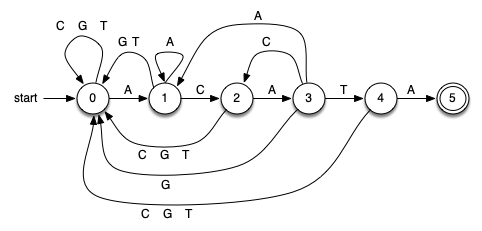 | 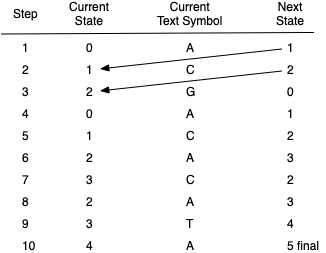 |


for intro check here:
- Deterministic Finite State Machines - Theory of Computation by TrevTutor: https://youtu.be/zF3RjLpYMUE?si=E4DfmONMY6ByIx0k
- Knuth-Morris-Pratt Algorithm Visually Explained by ByteQuest: https://youtu.be/ynv7bbcSLKE?si=W8tJ3y_izjo8ngAU
- Knuth-Morris-Pratt Algorithm by ByteQuest: https://youtu.be/q4_90fOoS-s?si=v125Iq2LBzExbm94



others:
- Coding Interview Solutions by NeetCode: https://www.youtube.com/playlist?list=PLot-Xpze53leF0FeHz2X0aG3zd0mr1AW_

**A Trace of the KMP Pattern Matcher**
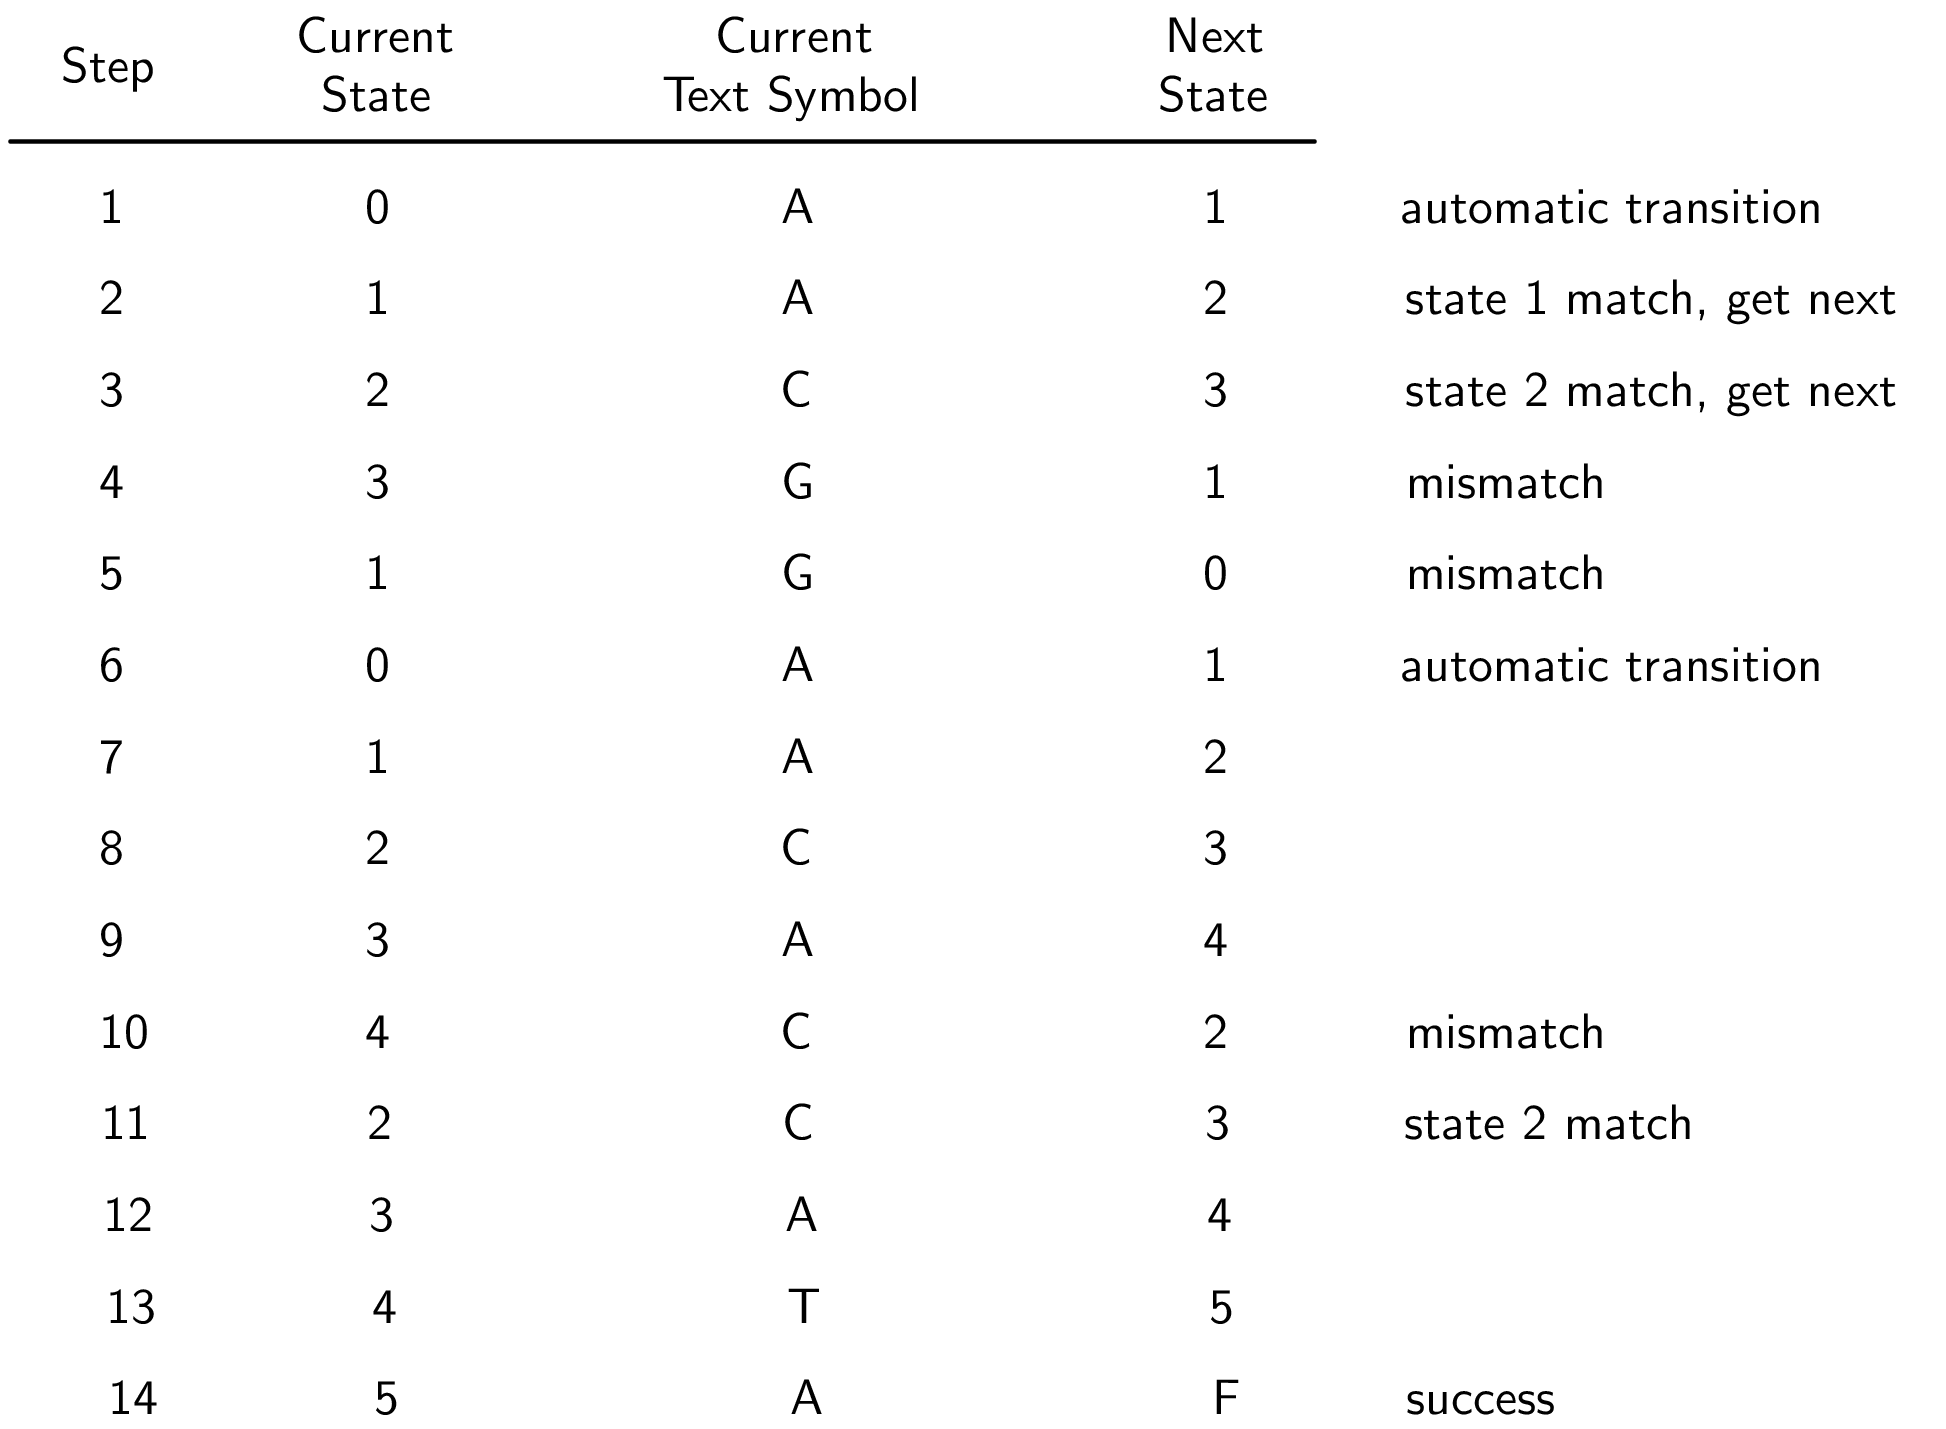

In [9]:
def simple_matcher(pattern, text):
    """
    Simple Pattern Matcher (Brute Force Approach)
    
    Time Complexity: O(n * m), where n is the length of text and m is the length of pattern.
    How it works:
    - Compares the pattern from left to right against the text.
    - If a character matches, advance both indices (j for pattern, i for text).
    - If a mismatch occurs, reset the pattern index (j = 0) and slide the text pointer 
      back relative to the mismatch, then continue.
    - Returns the starting index of the first match, or -1 if not found.
    """
    i = j = 0
    n = len(text)
    m = len(pattern)

    while i < n and j < m:
        if text[i] == pattern[j]:
            j += 1
        else:
            # On mismatch, reset pattern index and slide back in text to re-align
            i = i - j
            j = 0
        i += 1

        # Check if we successfully matched the entire pattern
        if j == m:
            return i - j

    return -1


def mismatched_links(pattern):
    """
    Computes KMP Mismatched Links (Prefix-Suffix Overlap Table).
    
    Why are these needed?
    When a mismatch occurs during KMP matching, we don't want to restart from scratch.
    Instead, we want to know how much of the current match can be reused (prefix-suffix overlap).
    This function returns a dictionary mapping each state (index) to its fallback destination state.
    """
    # Augment pattern with a placeholder '0' so indices match 1-based KMP graph states
    aug_pattern = "0" + pattern
    links = {1: 0}  # State 1 always falls back to state 0 (initial state)
    
    for k in range(2, len(aug_pattern)):
        s = links[k - 1]
        while s >= 1:
            if aug_pattern[s] == aug_pattern[k - 1]:
                break
            else:
                s = links[s]
        links[k] = s + 1
        
    return links


class KMPMatcher:
    """
    Knuth-Morris-Pratt (KMP) Pattern Matcher.
    
    Time Complexity: O(n) during the search phase because text characters are never re-scanned 
    backwards on a mismatch.
    """
    def __init__(self, pattern):
        self.pattern = pattern
        self.links = mismatched_links(pattern)

    def search(self, text):
        """
        Searches for the pattern in the text using the KMP matching strategy.
        Returns the starting index of the first occurrence, or -1 if not found.
        """
        m = len(self.pattern)
        n = len(text)
        
        if m == 0:
            return 0
            
        j = 0  # Pattern state/index
        i = 0  # Text index
        
        while i < n:
            # If text character matches the pattern character at state j
            if text[i] == self.pattern[j]:
                j += 1
                i += 1
                # If we reached the end of the pattern, we found a complete match!
                if j == m:
                    return i - m
            else:
                # Mismatch occurred: use KMP mismatched links to determine slide/fallback state
                if j > 0:
                    # Look up the fallback state from our dictionary
                    j = self.links[j + 1] - 1  # Adjusted for 0-indexed string matching vs 1-based states
                else:
                    # If we are at state 0, just advance the text pointer
                    i += 1
                    
        return -1

In [10]:
# Test text and pattern from the textbook examples
text = "ACGACACATA"
pattern = "ACATA"

# 1. Simple Matcher Test
print("Simple Matcher Index:", simple_matcher(pattern, text))  # Output: 5

# 2. Mismatched Links Test
print("Mismatched Links Dictionary:", mismatched_links(pattern))
# Output: {1: 0, 2: 1, 3: 1, 4: 2, 5: 1}

# 3. KMP Matcher Test
kmp = KMPMatcher(pattern)
print("KMP Matcher Index:", kmp.search(text))  # Output: 5

# Test with built-in Python string find for comparison
print("Python built-in find:", text.find(pattern))  # Output: 5

Simple Matcher Index: 5
Mismatched Links Dictionary: {1: 0, 2: 1, 3: 1, 4: 2, 5: 1}
KMP Matcher Index: 5
Python built-in find: 5
